# Neural style transfer on yoga poses

**Goal.** Re-render yoga photos in the style of famous paintings **without losing the pose**, and
measure how different artworks and settings trade artistic effect against pose preservation.

**Method** — Gatys, Ecker & Bethge (2016), implemented from scratch in PyTorch
(`src/style_transfer/`). A generated image *x* is optimised in pixel space to minimise

$$\mathcal{L}(x) = \alpha\,\mathcal{L}_{content}(x, c) + \beta\,\mathcal{L}_{style}(x, s) + \gamma\,\mathcal{L}_{TV}(x)$$

* **content** — MSE between VGG-19 `conv4_2` feature maps of *x* and the yoga photo *c*;
* **style** — MSE between **Gram matrices** $G = FF^\top / (C\,H\,W)$ of *x* and the artwork *s* at
  `conv1_1, conv2_1, conv3_1, conv4_1, conv5_1` (feature correlations = texture & colour, no layout);
* **total variation** — a small smoothness prior.

VGG-19 (ImageNet weights) is frozen; max-pooling is swapped for average-pooling as in the paper; *x*
starts from the content photo and is optimised with L-BFGS (300 iterations, 384 px, ≈ 17 s per image
on an Apple-silicon GPU).

### Assumptions
* Content images come from the **same cleaned Yoga-107 dataset** used for classification and
  search — one held-out *test* photo for each of six poses with clear, varied silhouettes, chosen
  automatically as the photo whose skeleton a keypoint detector finds most confidently.
* Five **public-domain** artworks spanning different visual vocabularies (swirling strokes, flat
  woodblock, expressionist colour, abstraction, impressionist haze).
* "Pose preserved" is measured **objectively** (below), not only by eye.

### How results are scored (`src/style_transfer/pose_metrics.py`)
| metric | meaning |
|---|---|
| **pose OKS** ↑ | COCO *Object Keypoint Similarity* between the 17 body keypoints Keypoint R-CNN detects on the photo vs. on the stylised image (1 = same skeleton) |
| **pose retrieved** ↑ | does the pose search engine (dense + reranker) still recognise the pose (kNN vote over the top 10)? |
| **SSIM** ↑ | grayscale structural similarity to the photo (pixel-level structure) |
| **content dist.** ↓ | relative `conv4_2` feature distance to the photo |
| **style dist.** ↓ | log₁₀ Gram-matrix distance to the artwork |

In [1]:
import sys

sys.path.insert(0, "..")  # repo root, so  imports work from notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image

from src.data.pose_names import display_name
from src.style_transfer.optimizer import StyleTransfer
from src.style_transfer.study import base_params, load_content_table
from src.style_transfer.vgg_features import VGG19_LAYERS, load_image
from src.utils.config_loader import get_path, load_config
from src.utils.device import get_device

RUN_DEMO = True  # one live style-transfer run (~20 s on MPS, a few minutes on CPU)
RECOMPUTE = False  # True → re-run the whole 48-image study (~17 min on MPS)

config = load_config()
STYLES = config["style_transfer"]["styles"]
STYLES_DIR = get_path(config, "styles_dir")
RES = get_path(config, "output_dir") / "metrics"
FIG = get_path(config, "output_dir") / "figures"
pd.set_option("display.precision", 3)
device = get_device(config["project"]["device"])
print("device:", device)

device: mps


## 1. Content and style images

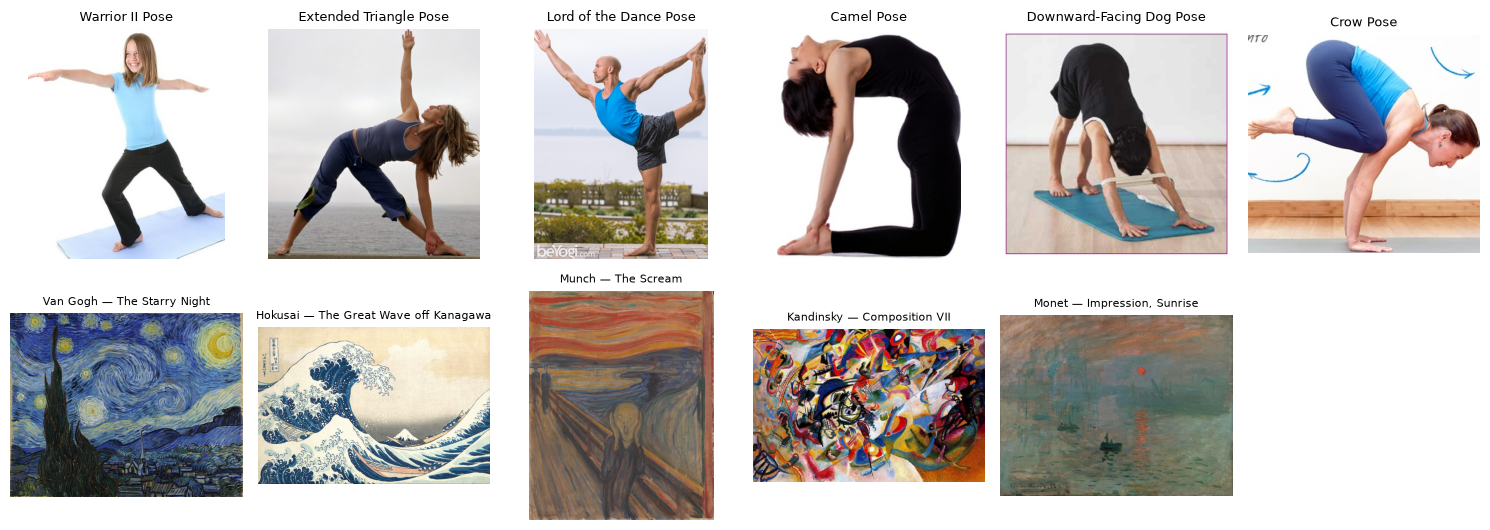

In [2]:
contents = load_content_table(config)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for ax, (_, c) in zip(axes[0], contents.iterrows(), strict=False):
    ax.imshow(Image.open(c.abs_path))
    ax.set_title(display_name(c.pose).split(" (")[1].rstrip(")"), fontsize=9)
    ax.axis("off")
for ax, (key, title) in zip(axes[1], STYLES.items(), strict=False):
    ax.imshow(Image.open(STYLES_DIR / f"{key}.jpg"))
    ax.set_title(title.split(" (")[0], fontsize=8)
    ax.axis("off")
axes[1, -1].axis("off")
plt.tight_layout()
plt.show()

## 2. The algorithm, live

One run of the optimiser with the default settings (β/α = 10⁶), showing how content and style
losses evolve. `StyleTransfer` builds the truncated VGG-19 once and can be reused for many images.

VGG-19 layers used: {'conv1_1': 0, 'conv2_1': 5, 'conv3_1': 10, 'conv4_1': 19, 'conv4_2': 21, 'conv5_1': 28}


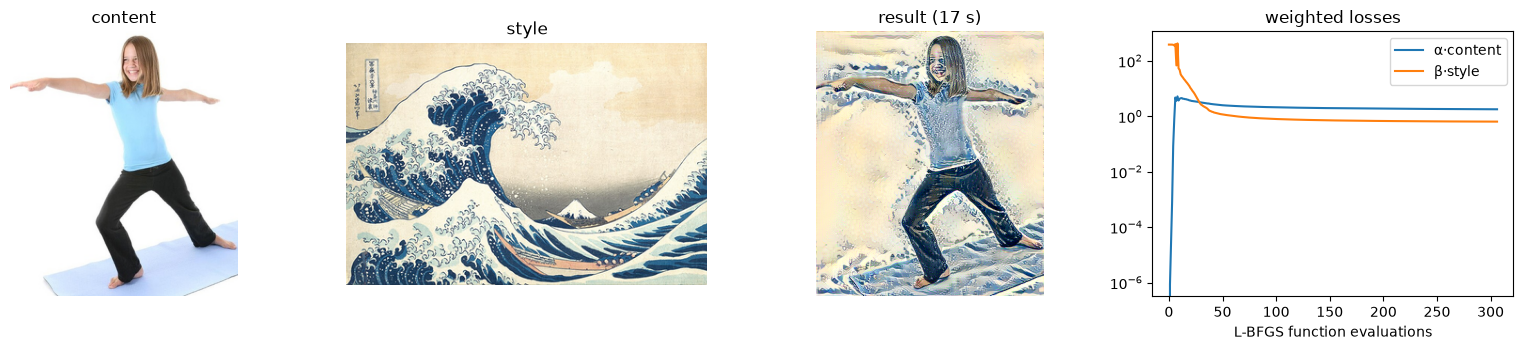

In [3]:
print("VGG-19 layers used:", {k: v for k, v in VGG19_LAYERS.items() if k in StyleTransfer.ALL_LAYERS})
if RUN_DEMO:
    params = base_params(config)
    st = StyleTransfer(device)
    content = load_image(contents.abs_path.iloc[0], params.size)
    style = load_image(str(STYLES_DIR / "great_wave.jpg"), params.size)
    res = st.run(content, style, params)
    h = pd.DataFrame(res.history)
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
    for ax, img, t in zip(
        axes[:3], (content, style, res.image), ("content", "style", f"result ({res.seconds:.0f} s)"), strict=False
    ):
        ax.imshow(img)
        ax.set_title(t)
        ax.axis("off")
    axes[3].plot(h.content * params.content_weight, label="α·content")
    axes[3].plot(h["style"] * params.style_weight, label="β·style")
    axes[3].set_yscale("log")
    axes[3].set_xlabel("L-BFGS function evaluations")
    axes[3].legend()
    axes[3].set_title("weighted losses")
    plt.tight_layout()
    plt.show()

## 3. Six poses × five artworks

Every cell is annotated with the pose OKS and whether the search index still recognises the pose
(✓/✗).

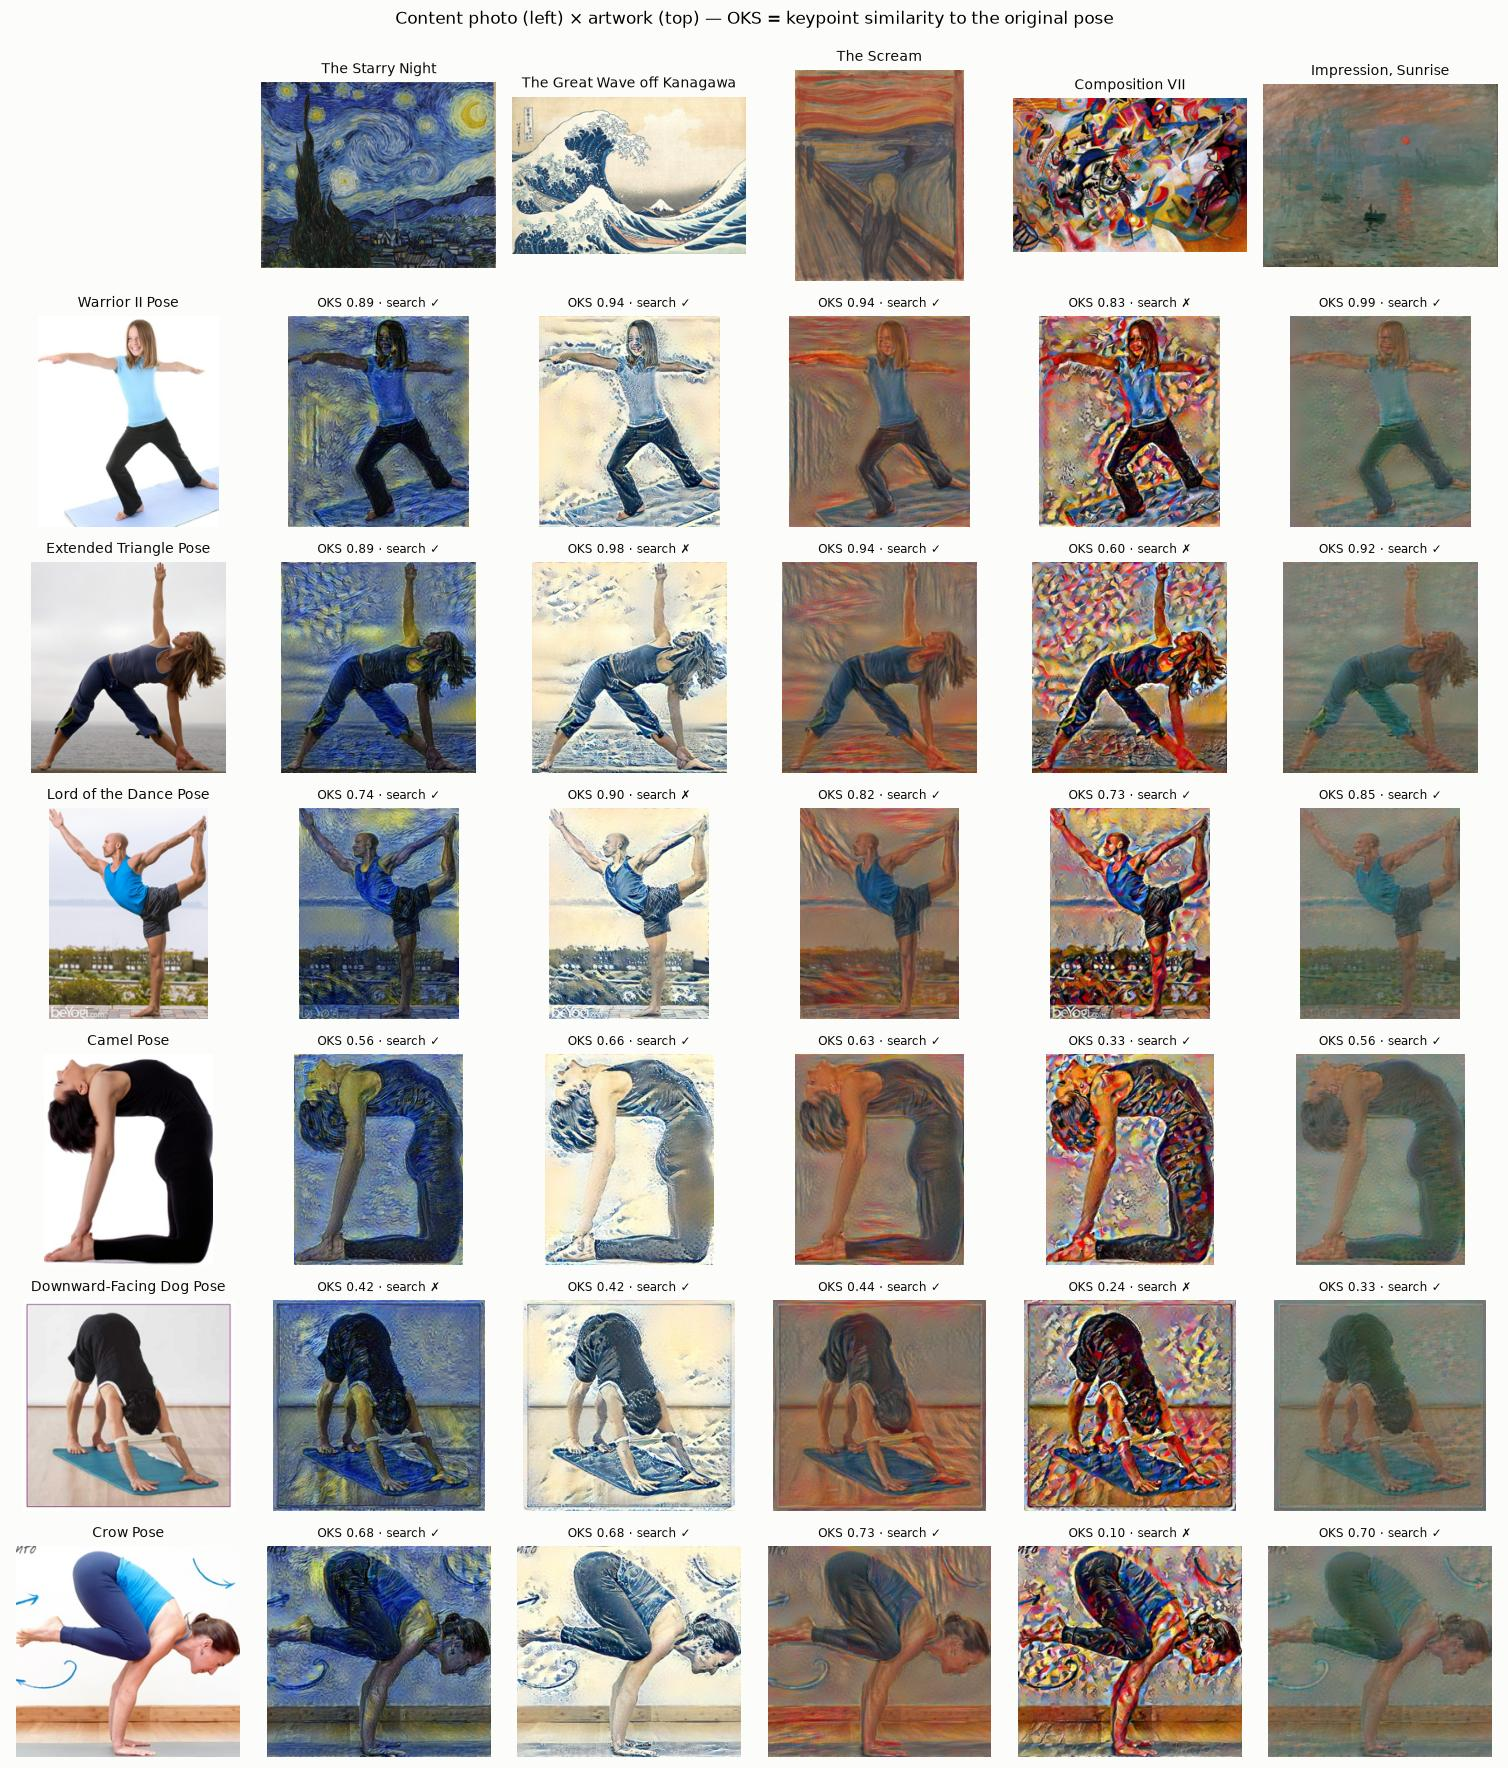

In [4]:
if RECOMPUTE:
    import run_pipeline as rp

    rp.run_style_transfer(config)
runs = pd.read_csv(RES / "style_runs.csv")
display(IPImage(FIG / "style_grid.jpg"))

In [5]:
summary = pd.read_csv(RES / "style_summary_by_style.csv", index_col=0)
display(summary)
orig = runs[runs.experiment == "original"]
print(
    f"Unstylised photos: search recognises {orig.pose_retrieved.mean():.0%} of the 6 poses; "
    f"mean person score {orig.person_score.mean():.3f}"
)

,artwork,pose_oks,ssim,content_dist,style_dist_log10,person_score,pose_retrieved,seconds
style,,,,,,,,
great_wave,Hokusai — The Great Wave off Kanagawa (c. 1831),0.764,0.450,0.353,-4.895,0.924,0.667,18.167
the_scream,Munch — The Scream (1893),0.749,0.390,0.314,-6.223,0.976,1.000,17.950
impression_sunrise,"Monet — Impression, Sunrise (1872)",0.727,0.431,0.292,-6.306,0.962,1.000,17.850
starry_night,Van Gogh — The Starry Night (1889),0.697,0.235,0.327,-5.875,0.928,0.833,18.200
composition_vii,Kandinsky — Composition VII (1913),0.472,0.266,0.436,-4.906,0.888,0.333,18.067


Unstylised photos: search recognises 67% of the 6 poses; mean person score 0.998


In [6]:
grid = runs[runs.experiment == "grid"].copy()
grid["pose_name"] = grid.pose.map(lambda p: display_name(p).split(" (")[1].rstrip(")"))
display(grid.pivot_table(index="pose_name", columns="style", values="pose_oks").round(2))

style,composition_vii,great_wave,impression_sunrise,starry_night,the_scream
pose_name,,,,,
Camel Pose,0.33,0.66,0.56,0.56,0.63
Crow Pose,0.10,0.68,0.70,0.68,0.73
Downward-Facing Dog Pose,0.24,0.42,0.33,0.42,0.44
Extended Triangle Pose,0.60,0.98,0.92,0.89,0.94
Lord of the Dance Pose,0.73,0.90,0.85,0.74,0.82
Warrior II Pose,0.83,0.94,0.99,0.89,0.94


## 4. Tuning the content/style trade-off (β/α)

The style weight is swept over four orders of magnitude for two (pose, artwork) pairs.

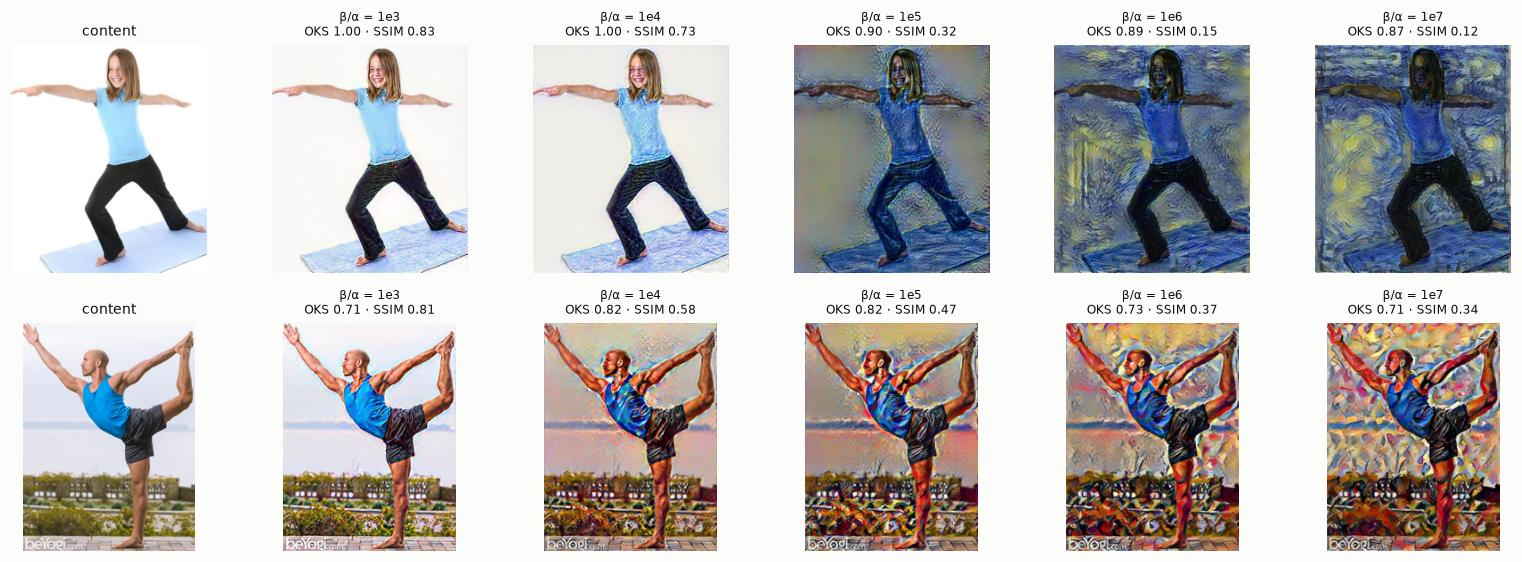

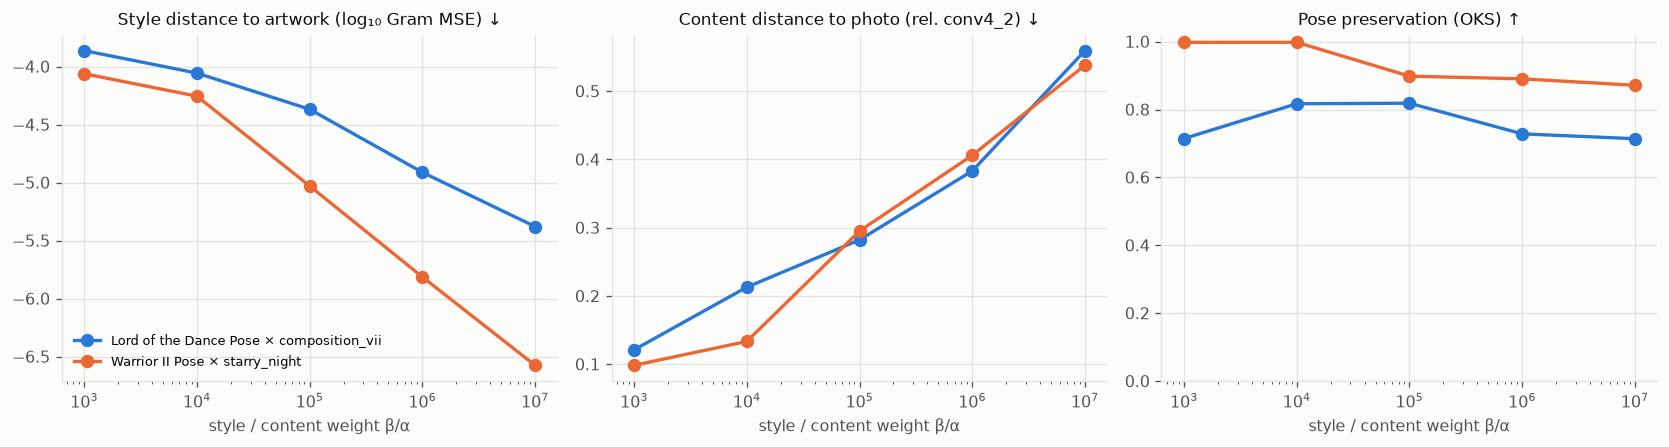

,pose,style,tag,content_dist,style_dist_log10,ssim,pose_oks,pose_retrieved
30,virabhadrasana ii,starry_night,sw1e+03,0.098,-4.061,0.832,0.998,True
31,virabhadrasana ii,starry_night,sw1e+04,0.133,-4.255,0.732,0.998,True
32,virabhadrasana ii,starry_night,sw1e+05,0.295,-5.029,0.322,0.898,True
33,virabhadrasana ii,starry_night,sw1e+06,0.406,-5.813,0.151,0.891,True
34,virabhadrasana ii,starry_night,sw1e+07,0.538,-6.575,0.118,0.872,True
35,natarajasana,composition_vii,sw1e+03,0.121,-3.862,0.806,0.715,False
36,natarajasana,composition_vii,sw1e+04,0.213,-4.056,0.583,0.817,True
37,natarajasana,composition_vii,sw1e+05,0.282,-4.368,0.467,0.819,False
38,natarajasana,composition_vii,sw1e+06,0.383,-4.911,0.370,0.728,True
39,natarajasana,composition_vii,sw1e+07,0.559,-5.379,0.340,0.714,True


In [7]:
display(IPImage(FIG / "style_weight_sweep.jpg"))
display(IPImage(FIG / "style_weight_tradeoff.png"))
sw = runs[runs.experiment == "weights"][
    ["pose", "style", "tag", "content_dist", "style_dist_log10", "ssim", "pose_oks", "pose_retrieved"]
]
display(sw)

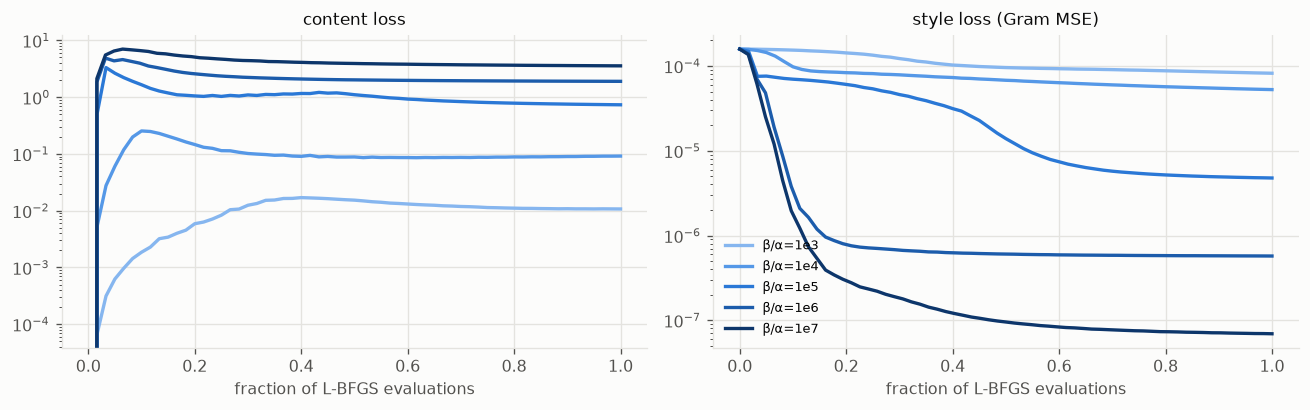

In [8]:
display(IPImage(FIG / "style_loss_curves.png"))

## 5. Which VGG layers define "style"? And does initialisation matter?

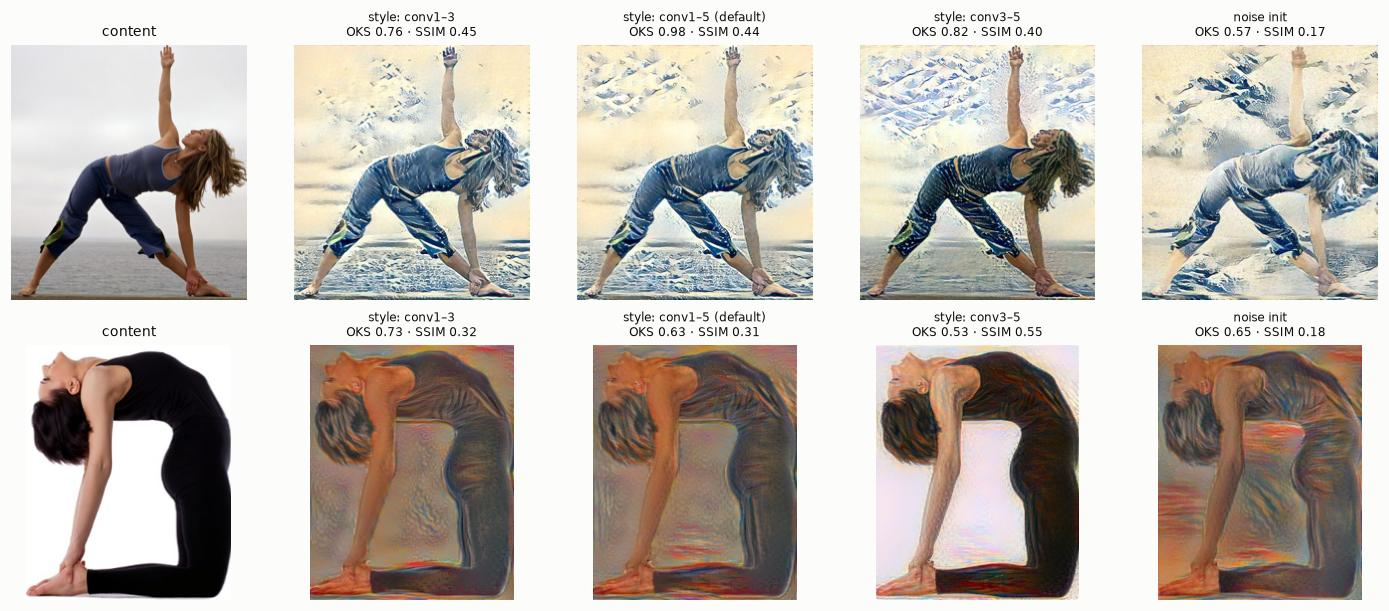

,pose,style,experiment,tag,ssim,pose_oks,style_dist_log10,pose_retrieved,seconds
40,utthita trikonasana,great_wave,layers,all,0.436,0.978,-4.969,False,18.8
41,utthita trikonasana,great_wave,layers,shallow,0.452,0.765,-4.884,False,16.7
42,utthita trikonasana,great_wave,layers,deep,0.401,0.823,-4.349,False,15.9
43,utthita trikonasana,great_wave,init,noise,0.172,0.570,-4.815,False,37.9
44,ustrasana,the_scream,layers,all,0.305,0.626,-6.119,True,16.5
45,ustrasana,the_scream,layers,shallow,0.321,0.726,-5.194,True,15.0
46,ustrasana,the_scream,layers,deep,0.548,0.529,-4.845,True,14.7
47,ustrasana,the_scream,init,noise,0.179,0.647,-6.097,True,33.3


In [9]:
display(IPImage(FIG / "style_layer_ablation.jpg"))
display(
    runs[runs.experiment.isin(["layers", "init"])][
        ["pose", "style", "experiment", "tag", "ssim", "pose_oks", "style_dist_log10", "pose_retrieved", "seconds"]
    ]
)

## 6. Discussion: how different styles affect the poses

**Reading OKS correctly.** Keypoint similarity depends on the *pose* as well as the style. Downward
Dog (0.24–0.44) and Camel (0.33–0.66) score low under every artwork. Even the lightest stylisation of Lord of the
Dance (β/α = 10³, visually almost identical to the photo) scores only 0.71, because the detector
re-places occluded or ambiguous joints on folded and inverted bodies. Artworks are therefore best
compared **within a pose** (the OKS pivot table above), where the ranking is very consistent.

**Per artwork** (averaged over the six poses):

* **Hokusai, *The Great Wave*: best pose preservation (OKS 0.76, highest SSIM 0.45).** Flat areas
  and strong dark outlines on a light ground keep the silhouette crisp, and the body reads almost
  like a woodblock print. The wave crests land in the background, not on the limbs. The search
  engine still recognises only 4 of 6, though: both misses land on a *sibling* pose (Triangle →
  Revolved Triangle, Lord of the Dance → Extended Hand-to-Big-Toe). The skeleton survives, but
  the fine detail that separates siblings does not.
* **Munch, *The Scream* (OKS 0.75) and Monet, *Impression, Sunrise* (0.73).** Both palettes are
  smooth and low in texture. They recolour the scene (Munch's orange-and-blue sky, Monet's grey-green
  haze) without breaking edges. Monet is the subtlest transfer and often looks like a colour grade.
  These are the two styles for which the search engine recognised **all six poses**.
* **Van Gogh, *The Starry Night* (OKS 0.70, lowest SSIM 0.24).** The swirling high-frequency strokes
  cover the whole frame and the body, which costs pixel structure (SSIM). The skeleton mostly
  survives, because the strokes follow the existing edges (5 of 6 recognised).
* **Kandinsky, *Composition VII*: worst on every pose (OKS 0.47, 0.10 on Crow).** Its Gram
  statistics are hard-edged, saturated, multi-coloured fragments with no figure–ground separation.
  Stamped over the whole image, they break the body into confetti and camouflage limbs against the
  background. Compact poses with overlapping limbs (Crow, Downward Dog, Camel) suffer
  most, and the search engine recognises only 2 of 6.

**Content/style weight.** Raising β/α from 10³ to 10⁷ moves the result smoothly from photo to
painting. Style distance falls by about 2.5 orders of magnitude, content distance rises 5×, and SSIM
drops from 0.83 to 0.12 for Warrior II. Pose OKS, however, barely moves (Warrior II: 1.00 → 0.87).
Starting the optimisation **from the content photo** keeps the geometry pinned even when the style
term dominates. Most of the stylisation happens between 10⁴ and 10⁶. We use **10⁶** as the default:
the brush-strokes are clearly the artwork's, and the pose is still detected and retrieved.

**Style layers.** Gram matrices from only the **shallow** layers (conv1–3) transfer colour and fine
grain. Only the **deep** layers (conv3–5) transfer larger motifs and leave the original colours.
Using all five (the paper's default) gives the most convincing "painting" and kept the Triangle
pose best (OKS 0.98). Neither alternative is uniformly better for pose preservation.

**Initialisation.** Starting from **white noise** (600 iterations, 2× the time) gives the most
painterly look. It also loses the most structure (SSIM 0.17–0.18 vs. 0.31–0.44) and pose fidelity
on the Triangle pose (OKS 0.57 vs. 0.98). Content initialisation is both faster and more faithful.

**Does the pose survive stylisation, according to the search engine?** The search engine
(dense retrieval + reranker, kNN vote over the top 10) recognises the pose for **23 of 30 stylised
images (77%)**. On the six unstylised photos it gets 4 of 6: it confuses the original Downward Dog
with Wide-Legged Forward Bend, and Lord of the Dance with its sibling Extended Hand-to-Big-Toe. A
detector still finds a person in every stylised image (mean confidence 0.94). So, except for
Kandinsky, style transfer at these settings changes *how* the pose looks far more than *which*
pose it is.

**Takeaways.** Styles with **clear figure–ground separation and low-frequency texture** (woodblock,
expressionist colour fields, impressionist haze) preserve yoga poses well. **Dense, high-contrast,
all-over textures** (Kandinsky's abstraction, and to a lesser degree Van Gogh's strokes) erode
them, most of all for compact poses with overlapping limbs. If pose fidelity matters, for example
for instruction material, use content initialisation, β/α ≤ 10⁶ and a low-texture artwork.
Otherwise, Van Gogh at 10⁶–10⁷ gives the most striking images. A further option is a
foreground mask, so the style term doesn't paint over the body.